# capy — Examples

A walkthrough of the full capy workflow: data model → comfort models → metrics → visualization.

**Sections**
1. [Native data format](#1-native-data-format) — `SpatialGrid`, `OccupancySchedule`, `ThermalEnvironment`
2. [Comfort models](#2-comfort-models) — Empirical, PMV, Adaptive
3. [Visualization](#3-visualization) — floor maps, hourly heatmaps

All examples use synthetic data — no simulation software or EPW file required.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd

from capy.core.grid import SpatialGrid
from capy.core.schedule import OccupancySchedule
from capy.core.environment import ThermalEnvironment

---
## 1. Native data format

Three objects underpin every capy workflow:

| Object | Role | Key input |
|---|---|---|
| `SpatialGrid` | Where are the sensors? (one zone) | `(n, 3)` points + area per point |
| `OccupancySchedule` | When is the space occupied? | 8760-length boolean mask |
| `ThermalEnvironment` | What are the conditions? | Dict of `(n_points, 8760)` arrays |

All downstream metrics accept a `ThermalEnvironment` and optionally an `OccupancySchedule` — nothing else.

### 1.1 SpatialGrid

A `SpatialGrid` describes sensor positions **for one zone**. Every point has:
- a coordinate `(x, y, z)` in metres
- a floor area in m² it represents

Each grid also carries a `zone_id` (opaque identifier) and a `zone_name` (human-readable label).

In [2]:
# 3×4 rectangular grid — 12 sensor points, 1 m² each
xs = np.tile(np.arange(3), 4).astype(float)
ys = np.repeat(np.arange(4), 3).astype(float)
zs = np.full(12, 0.8)                          # sensor height 0.8 m (seated)

points = np.column_stack([xs, ys, zs])          # (12, 3)
areas  = np.ones(12)                            # 1 m² per point

grid = SpatialGrid(
    points=points, areas=areas,
    zone_id="office_south", zone_name="Office, South",
)
print(grid)
print(f"Points: {grid.n_points}  |  Total area: {grid.total_area} m²")

SpatialGrid(zone='Office, South', n_points=12, total_area=12.0 m²)
Points: 12  |  Total area: 12.0 m²


In [3]:
# from_points() assigns uniform areas — useful when all points represent the same cell size
pts = np.random.rand(20, 3) * [10, 8, 0]
grid_open = SpatialGrid.from_points(pts, unit_area=0.5, zone_id=1, zone_name="Open Plan")
print(grid_open)

SpatialGrid(zone='Open Plan', n_points=20, total_area=10.0 m²)


In [4]:
# Each SpatialGrid = one zone. Multi-zone analysis means iterating over a list.
grid_meeting = SpatialGrid.from_points(
    np.random.rand(8, 3) * [4, 3, 0],
    unit_area=0.75, zone_id="meeting_01", zone_name="Meeting Room, North",
)

for g in [grid, grid_meeting]:
    print(f"{g.zone_name:25s}  id={g.zone_id}  {g.n_points} pts  {g.total_area:.1f} m²")

Office, South              id=office_south  12 pts  12.0 m²
Meeting Room, North        id=meeting_01  8 pts  6.0 m²


### 1.2 OccupancySchedule

A boolean mask over all 8760 hours of the year. `True` = occupied.

In [5]:
# Standard factory methods
office   = OccupancySchedule.work_hours(start_hour=8, end_hour=18)
always   = OccupancySchedule.always()
lecture  = OccupancySchedule.from_hours([9, 11, 14, 16])

for sched in [office, always, lecture]:
    print(sched)

OccupancySchedule(occupied=2610h / 8760h, 29.8%)
OccupancySchedule(occupied=8760h / 8760h, 100.0%)
OccupancySchedule(occupied=1460h / 8760h, 16.7%)


In [6]:
idx = office.as_indices()
print(f"First 10 occupied hours: {idx[:10]}")
print(f"Occupied fraction: {office.occupied_fraction:.1%}")

First 10 occupied hours: [ 8  9 10 11 12 13 14 15 16 17]
Occupied fraction: 29.8%


### 1.3 ThermalEnvironment

The central data container — links a `SpatialGrid` to a dict of `(n_points, n_hours)` arrays.
Variable names are resolved through an alias table, so `"ta"`, `"tdb"`, and `"air_temperature"` all refer to the same thing.

In [7]:
N_POINTS = grid.n_points   # 12
N_HOURS  = 8760

hours    = np.arange(N_HOURS)
seasonal = 4 * np.sin(2 * np.pi * hours / N_HOURS - np.pi / 2)
diurnal  = 2 * np.sin(2 * np.pi * (hours % 24) / 24 - np.pi / 2)
base     = 22.0 + seasonal + diurnal                              # (8760,)

spatial_gradient = np.linspace(0, 3, N_POINTS)                   # (12,)
ta  = base[np.newaxis, :] + spatial_gradient[:, np.newaxis]      # (12, 8760)
mrt = ta + 2.0
rh  = np.full((N_POINTS, N_HOURS), 50.0)

env = ThermalEnvironment.from_arrays(
    grid=grid,
    variables={"ta": ta, "mrt": mrt, "rh": rh},
)
print(env)

ThermalEnvironment(n_points=12, n_hours=8760, variables=[air_temperature, mean_radiant_temperature, relative_humidity])


In [8]:
# Access by canonical name or alias
t_op = env.operative_temperature()   # computed as (ta + mrt) / 2 if not stored
print(f"operative_temperature shape: {t_op.shape}")
print(f"Point 0 annual mean:  {t_op[0].mean():.1f} °C")
print(f"Point 11 annual mean: {t_op[11].mean():.1f} °C  (warmer — spatial gradient)")

operative_temperature shape: (12, 8760)
Point 0 annual mean:  23.0 °C
Point 11 annual mean: 26.0 °C  (warmer — spatial gradient)


---
## 2. Comfort models

All three models take a `ThermalEnvironment` and return a `ComfortResult`:

| Model | Input | Strength |
|---|---|---|
| Empirical | operative temperature | Simple, no deps, fast |
| PMV | ta, mrt, rh, v | Standard ASHRAE / ISO |
| Adaptive | ta, mrt, prevailing outdoor temp | Mixed-mode / naturally ventilated buildings |

Every `ComfortResult` exposes the same interface regardless of model.

### 2.1 Empirical model

Classifies comfort using an operative temperature band derived from the ASHRAE Global Thermal Comfort Database II
(10th–90th percentile of temperatures where occupants expressed 'No change' preference).

Default band: **21–28 °C**.

In [9]:
from capy.comfort.empirical import calculate_empirical

result_emp = calculate_empirical(env)
print(result_emp)
print(f"\nvalues shape:  {result_emp.values.shape}   (operative temperature)")
print(f"discrete shape: {result_emp.discrete.shape}  (-1 = cold, 0 = ok, +1 = hot)")

ComfortResult(model='Empirical', band=(21.0, 28.0), shape=(12, 8760))

values shape:  (12, 8760)   (operative temperature)
discrete shape: (12, 8760)  (-1 = cold, 0 = ok, +1 = hot)


In [10]:
# Custom band
result_custom = calculate_empirical(env, lower=20.0, upper=26.0)

# Per-point comfort fraction (annual)
frac_annual = result_emp.comfort_fraction()
print(f"Annual comfort fraction (all hours):")
print(f"  min: {frac_annual.min():.1%}  max: {frac_annual.max():.1%}  mean: {frac_annual.mean():.1%}")

# Filtered to occupied hours only
schedule = OccupancySchedule.work_hours()
frac_occ = result_emp.comfort_fraction(schedule=schedule)
print(f"Occupied-hours comfort fraction:")
print(f"  min: {frac_occ.min():.1%}  max: {frac_occ.max():.1%}  mean: {frac_occ.mean():.1%}")

Annual comfort fraction (all hours):
  min: 63.8%  max: 67.4%  mean: 66.1%
Occupied-hours comfort fraction:
  min: 54.3%  max: 72.5%  mean: 65.4%


### 2.2 PMV model

Predicted Mean Vote via `pythermalcomfort`. Requires `air_temperature`, `mean_radiant_temperature`,
and `relative_humidity`. Air velocity falls back to 0.1 m/s if not in the environment.

Comfort band: **−0.5 ≤ PMV ≤ +0.5**.

In [11]:
from capy.comfort.pmv import calculate_pmv, PMVParameters

# Default parameters: met=1.1, clo=0.8, standard='ASHRAE'
result_pmv = calculate_pmv(env)
print(result_pmv)
print(f"\nPMV values range: {result_pmv.values.min():.2f} to {result_pmv.values.max():.2f}")

ComfortResult(model='PMV', band=(-0.5, 0.5), shape=(12, 8760))

PMV values range: -1.91 to 2.31


In [12]:
# Custom occupant parameters — e.g. light activity + summer clothing
summer_params = PMVParameters(met=1.2, clo=0.5, standard="ISO")
result_pmv_summer = calculate_pmv(env, params=summer_params)

frac_default = result_pmv.comfort_fraction(schedule=schedule)
frac_summer  = result_pmv_summer.comfort_fraction(schedule=schedule)
print(f"Default params — occupied comfort: {frac_default.mean():.1%}")
print(f"Summer params  — occupied comfort: {frac_summer.mean():.1%}")

Default params — occupied comfort: 36.1%
Summer params  — occupied comfort: 30.4%


### 2.3 Adaptive model

ASHRAE 55-2023 or EN 16798-1 adaptive comfort. Comfort temperature shifts with the
prevailing mean outdoor temperature, making it appropriate for naturally ventilated
and mixed-mode buildings.

| Standard | Formula | Default band |
|---|---|---|
| ASHRAE 55 | T_comf = 0.31 × T_prev + 17.8 | ±2.5 °C (90% acceptability) |
| EN 16798-1 | T_comf = 0.33 × T_prev + 18.8 | ±3 °C (Class II) |

Supply `epw_path=` for time-varying prevailing temperature, or `prevailing_mean_outdoor_temp=`
for a quick scalar override.

In [13]:
from capy.comfort.adaptive import calculate_adaptive

# ASHRAE 55 — scalar prevailing temp (no EPW needed)
result_ash = calculate_adaptive(env, standard="ashrae55", prevailing_mean_outdoor_temp=18.0)
print(result_ash)
print(f"\nApplicable hours: {result_ash.applicability_mask.mean():.0%}")
print(f"Comfort temperature (uniform): {result_ash.t_comf[0]:.2f} °C")

AdaptiveResult(model='adaptive_ashrae55_90%', band=±2.5°C, valid_hours=100%)

Applicable hours: 100%
Comfort temperature (uniform): 23.40 °C


In [14]:
# EN 16798-1 — three acceptability classes
r_i   = calculate_adaptive(env, standard="en16798", acceptance_band="I",   prevailing_mean_outdoor_temp=18.0)
r_ii  = calculate_adaptive(env, standard="en16798", acceptance_band="II",  prevailing_mean_outdoor_temp=18.0)
r_iii = calculate_adaptive(env, standard="en16798", acceptance_band="III", prevailing_mean_outdoor_temp=18.0)

for label, r in [("Class I  (±2°C)", r_i), ("Class II (±3°C)", r_ii), ("Class III (±4°C)", r_iii)]:
    print(f"{label}: occupied comfort = {r.comfort_fraction(schedule).mean():.1%}")

Class I  (±2°C): occupied comfort = 48.4%
Class II (±3°C): occupied comfort = 63.7%
Class III (±4°C): occupied comfort = 76.6%


In [15]:
# With a real EPW — time-varying prevailing temperature (uncomment and set path)
# result_epw = calculate_adaptive(env, epw_path="path/to/climate.epw")
# print(result_epw.t_prevailing[:24])  # first 24 hours of running mean

### 2.4 ComfortResult interface

All models return the same `ComfortResult` interface — metrics and visualizations
work identically regardless of which model produced it.

In [16]:
# Use whichever model you prefer — the downstream API is identical
result = result_emp

# Boolean mask — True where comfortable
comfortable = result.is_comfortable()          # (n_points, n_hours)
print(f"is_comfortable shape: {comfortable.shape}")
print(f"Overall comfort fraction: {comfortable.mean():.1%}")

# Per-point comfort fractions
annual_frac   = result.comfort_fraction()              # all 8760 hours
occupied_frac = result.comfort_fraction(schedule)      # occupied hours only

print(f"\nPer-point annual comfort (mean across all points): {annual_frac.mean():.1%}")
print(f"Per-point occupied comfort:                         {occupied_frac.mean():.1%}")

is_comfortable shape: (12, 8760)
Overall comfort fraction: 66.1%

Per-point annual comfort (mean across all points): 66.1%
Per-point occupied comfort:                         65.4%


In [17]:
# Compare comfort across models at the same location
models = [
    ("Empirical",      result_emp),
    ("PMV (ASHRAE)",   result_pmv),
    ("Adaptive",       result_ash),
]

print(f"{'Model':<20} {'Annual comfort':>15} {'Occupied comfort':>17}")
print("-" * 55)
for name, r in models:
    ann = r.comfort_fraction().mean()
    occ = r.comfort_fraction(schedule).mean()
    print(f"{name:<20} {ann:>14.1%} {occ:>16.1%}")

Model                 Annual comfort  Occupied comfort
-------------------------------------------------------
Empirical                     66.1%            65.4%
PMV (ASHRAE)                  34.2%            36.1%
Adaptive                      47.3%            46.9%


---
## 3. Visualization

Two core plot functions work with both `ThermalEnvironment` and `ComfortResult`.

In [18]:
from capy.viz.heatmap import plot_hourly_heatmap
from capy.viz.spatial import plot_floor_map

### 3.1 Floor map — spatial distribution

Annual statistic of any variable or comfort fraction plotted on the sensor grid plan.
Each point is sized by its represented floor area.

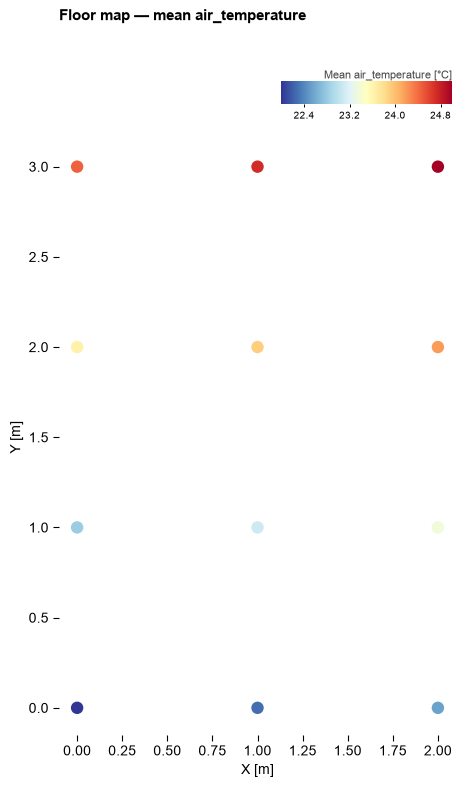

In [19]:
# Temperature distribution across the floor
fig = plot_floor_map(env, variable="air_temperature", annual_stat="mean")

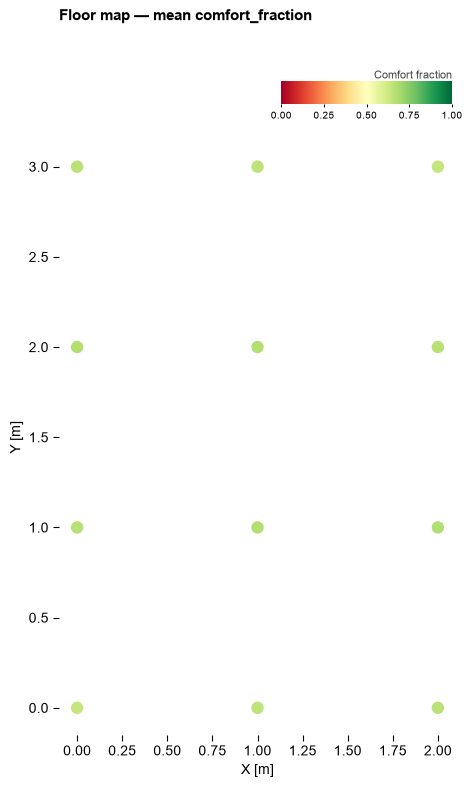

In [20]:
# Comfort fraction per point (annual)
fig = plot_floor_map(result_emp, variable="comfort_fraction")

### 3.2 Hourly heatmap — diurnal rhythm across the year

Day of year on the x-axis; hour of day on the y-axis (midnight at bottom).
Each cell shows the spatial mean across all points for that hour of that day.

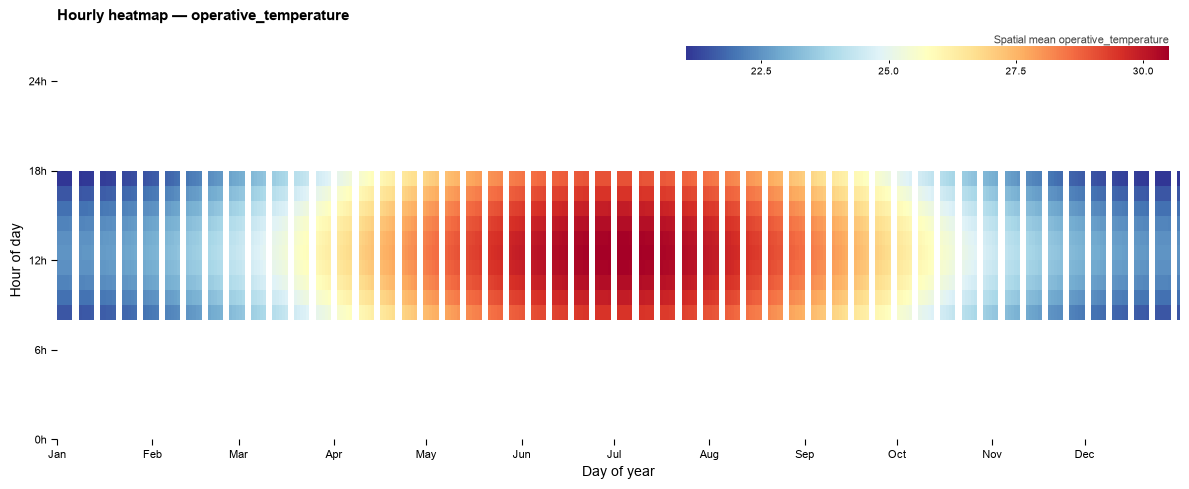

In [21]:
# Operative temperature — annual pattern
fig = plot_hourly_heatmap(env, variable="operative_temperature", schedule=schedule)

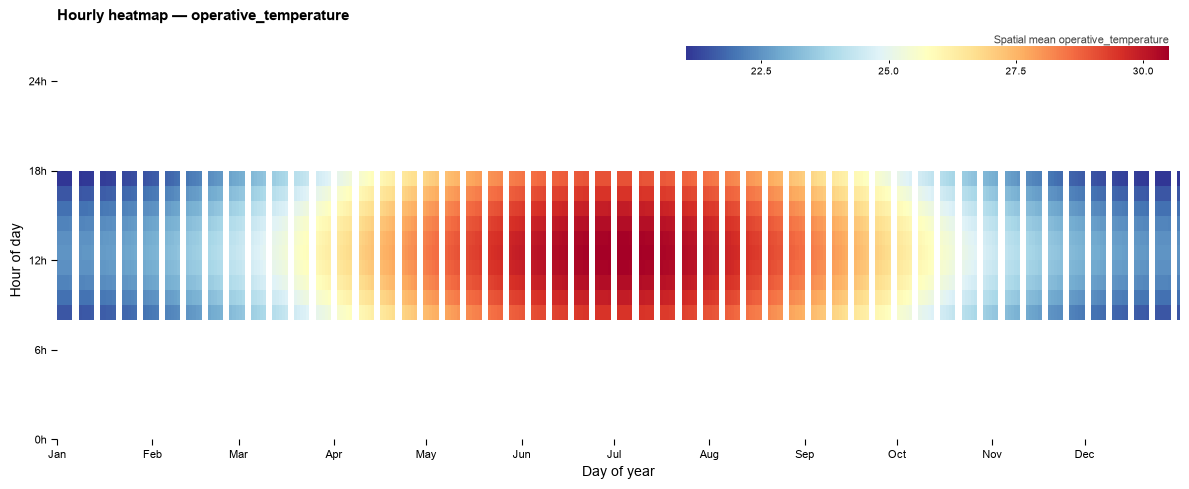

In [22]:
# Comfort classification heatmap
fig = plot_hourly_heatmap(result_emp, schedule=schedule)

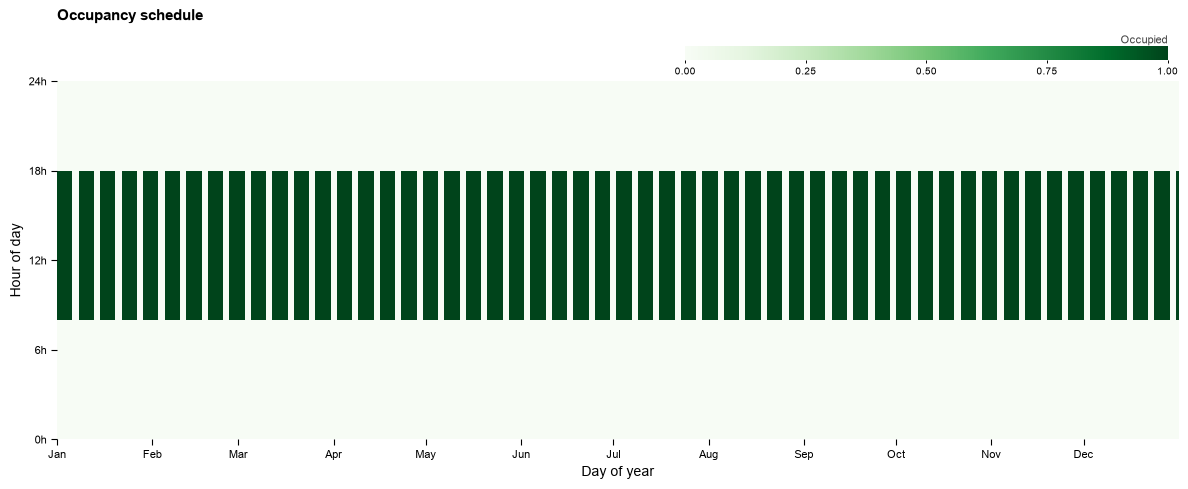

In [23]:
# Occupancy schedule — useful sanity check
fig = plot_hourly_heatmap(schedule)

---
## 4. Metrics

Five spatial metrics complement the comfort models:

| Metric | What it measures |
|---|---|
| `spatial_thermal_autonomy` (sTA) | % occupied hours where ≥ τ of floor area is comfortable |
| `spatial_variability` | Spatial temperature spread: variable / uniform / excessive |
| `diurnal_amplitude` | Daily ΔT per sensor point and day |
| `temperature_drift_rate` | Hour-to-hour temperature change rate |
| `diurnal_phase_alignment` | Indoor–outdoor daily cycle correlation (requires EPW) |

All metrics accept a `ThermalEnvironment` and an optional `OccupancySchedule`.

In [24]:
from capy.metrics import (
    spatial_thermal_autonomy,
    spatial_variability,
    diurnal_amplitude,
    temperature_drift_rate,
    diurnal_phase_alignment,
)
from capy.viz.timeline import plot_timeline, plot_seasonal_profile
from capy.viz.summary import plot_category_summary

### 4.1 Spatial Thermal Autonomy (sTA)

sTA answers: *"What fraction of occupied hours does the building provide comfortable conditions to at least τ = 80 % of its floor area simultaneously?"*

A high sTA means comfort is spatially inclusive, not just an average.

In [25]:
sta = spatial_thermal_autonomy(result_emp, tau=0.8, schedule=schedule)
print(sta)
print(f"\nsTA:           {sta.annual_pct:.1f} %")
print(f"tau threshold: {sta.tau}")
print(f"Hourly array:  shape {sta.hourly_array.shape}  range [{sta.hourly_array.min():.2f}, {sta.hourly_array.max():.2f}]")

sTAResult(annual_pct=52.5%, tau=80%, schedule_applied=True)

sTA:           52.5 %
tau threshold: 0.8
Hourly array:  shape (8760,)  range [0.00, 1.00]


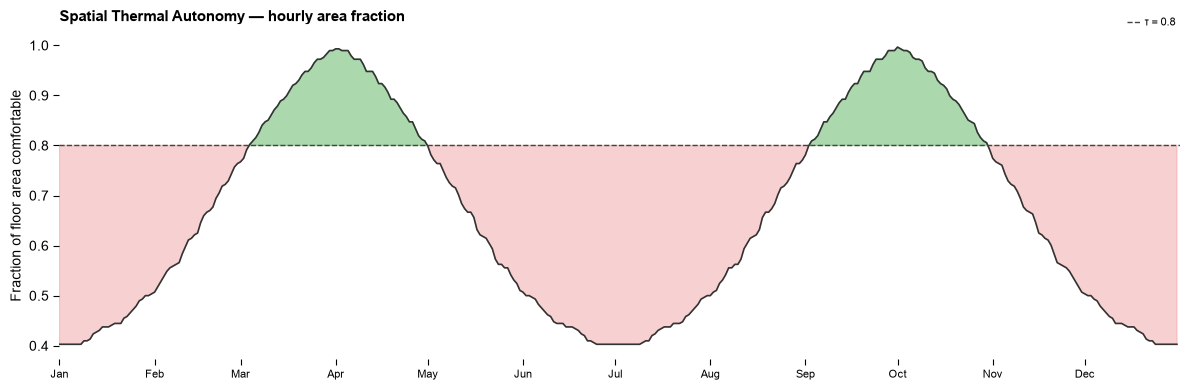

In [26]:
# Seasonal ribbon: fraction of floor area comfortable each occupied hour
# Green fill = hours where the tau threshold is met
fig = plot_timeline(
    sta.hourly_array,
    threshold=sta.tau,
    threshold_label=f"τ = {sta.tau}",
    ylabel="Fraction of floor area comfortable",
    title="Spatial Thermal Autonomy — hourly area fraction",
)

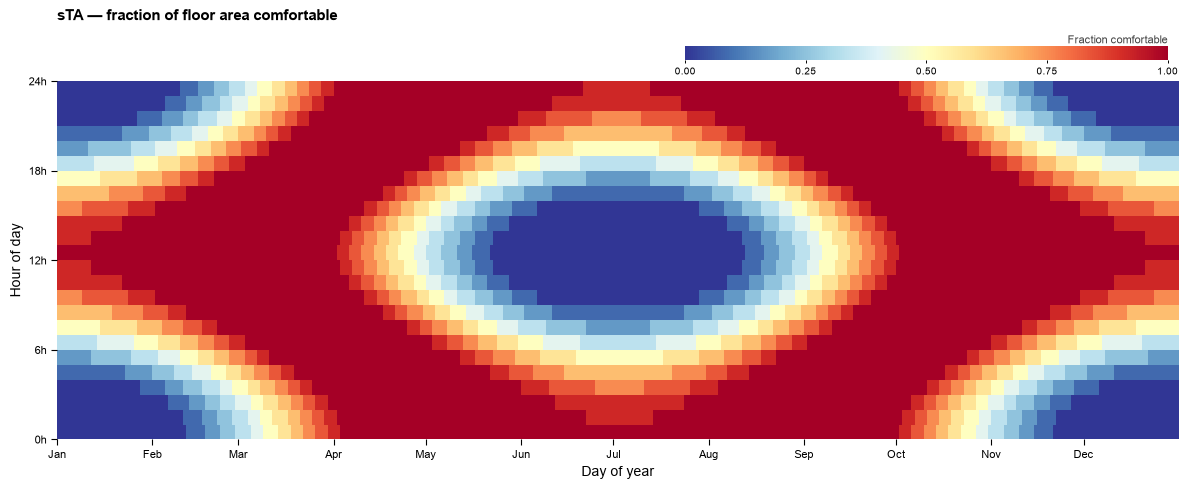

In [27]:
# Calendar view of the same series
fig = plot_hourly_heatmap(
    sta.hourly_array,
    label="Fraction comfortable",
    vmin=0.0, vmax=1.0,
    title="sTA — fraction of floor area comfortable",
)

### 4.2 Spatial Variability

The hourly spatial temperature range (max − min across sensor points) classifies how thermally varied the space is:

| Zone | Spatial range | Interpretation |
|---|---|---|
| Variable | δT_min – δT_max | Mild gradient — occupants can self-select positions |
| Uniform | < δT_min | Little variation — everyone experiences the same conditions |
| Excessive | > δT_max | Large spread — meaningful discomfort differences |

Default thresholds: **δT_min = 2 °C, δT_max = 4 °C**.

In [28]:
sv = spatial_variability(env, schedule=schedule)
print(sv)
print(f"\nMedian spatial range:  {sv.median_spatial_range:.2f} °C")
print(f"Fraction variable:     {sv.fraction_variable:.1f} %")
print(f"Fraction uniform:      {sv.fraction_uniform:.1f} %")
print(f"Fraction excessive:    {sv.fraction_excessive:.1f} %")

SpatialVariabilityResult(variable=100.0%, uniform=0.0%, excessive=0.0%, median_range=3.00°C)

Median spatial range:  3.00 °C
Fraction variable:     100.0 %
Fraction uniform:      0.0 %
Fraction excessive:    0.0 %


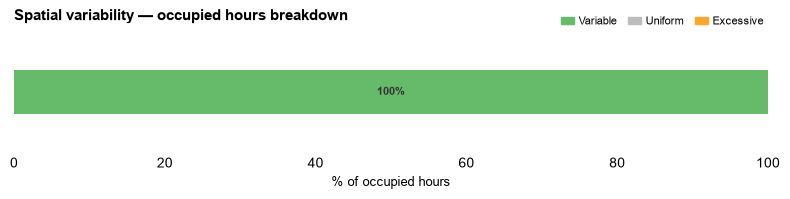

In [29]:
# Stacked bar: breakdown of occupied hours by variability category
fig = plot_category_summary(
    categories=[
        {"label": "Variable",  "value": sv.fraction_variable,  "color": "#66bb6a"},
        {"label": "Uniform",   "value": sv.fraction_uniform,   "color": "#bdbdbd"},
        {"label": "Excessive", "value": sv.fraction_excessive, "color": "#ffa726"},
    ],
    title="Spatial variability — occupied hours breakdown",
)

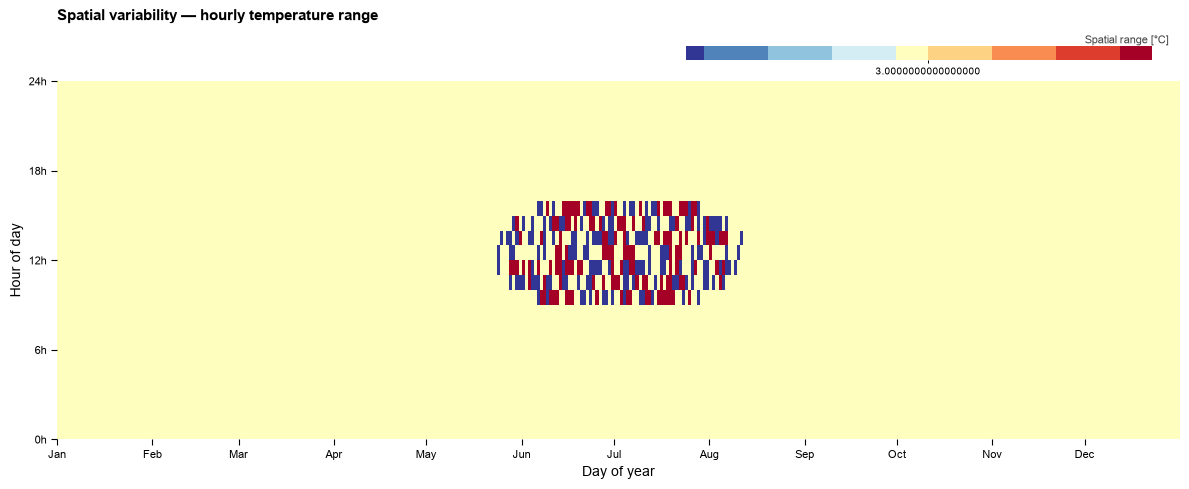

In [30]:
# Calendar heatmap of spatial range — compute without schedule to get 8760-element series
sv_full = spatial_variability(env)
fig = plot_hourly_heatmap(
    sv_full.hourly_range,
    label="Spatial range [°C]",
    title="Spatial variability — hourly temperature range",
)

### 4.3 Diurnal Amplitude

The daily temperature swing (max − min per 24-hour day) per sensor point. A 2–4 °C daily amplitude is associated with positive alliesthesia — mild thermal stimulation that maintains occupant alertness and comfort perception.

In [31]:
amp = diurnal_amplitude(env, schedule=schedule, target_min=2.0, target_max=4.0)
print(amp)
print(f"\nAmplitude matrix:       shape {amp.amplitude_matrix.shape}  (points × days)")
print(f"Median amplitude grid:  {amp.median_amplitude_grid:.2f} °C  (grid-level summary)")
print(f"Fraction in 2–4 °C:     {amp.fraction_in_target:.1f} %")

DiurnalAmplitudeResult(median_grid=4.00°C, in_target=49.8%)

Amplitude matrix:       shape (12, 365)  (points × days)
Median amplitude grid:  4.00 °C  (grid-level summary)
Fraction in 2–4 °C:     0.5 %


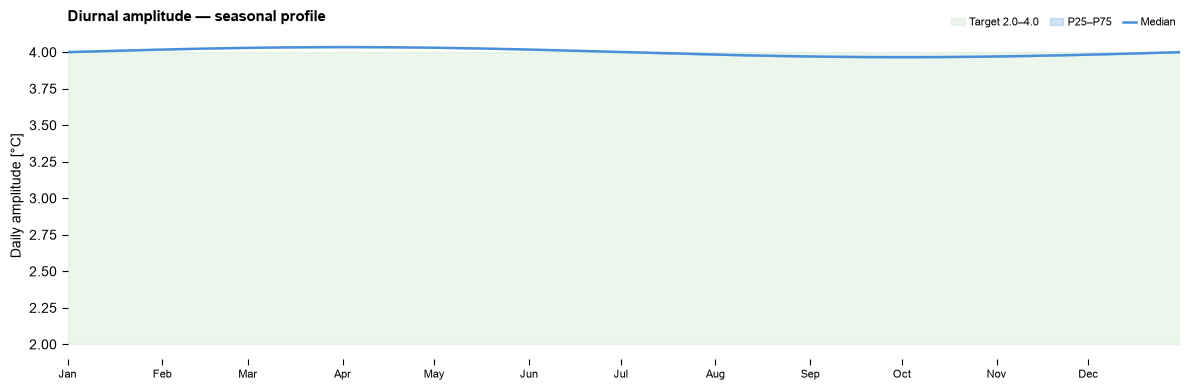

In [32]:
# Seasonal profile: median daily amplitude per day with P25–P75 spread across sensor points
# Green band = evidence-based beneficial range (2–4 °C)
fig = plot_seasonal_profile(
    amp.amplitude_matrix,
    target_range=(amp.target_min, amp.target_max),
    ylabel="Daily amplitude [°C]",
    title="Diurnal amplitude — seasonal profile",
)

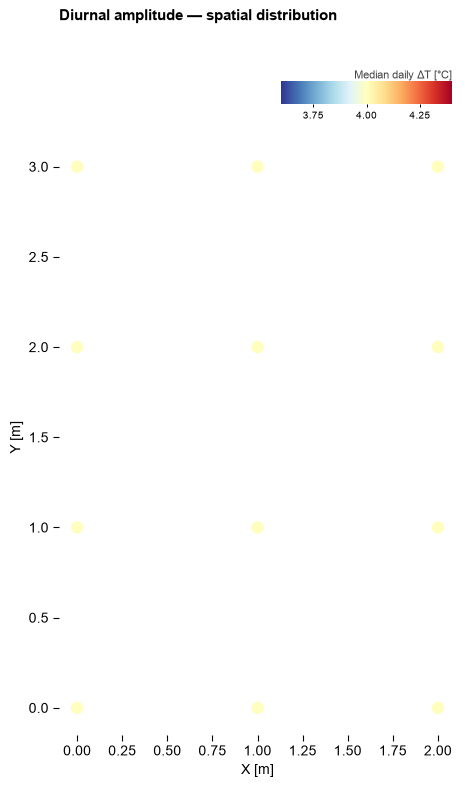

In [33]:
# Spatial map: median annual amplitude per sensor point
fig = plot_floor_map(
    values=amp.median_amplitude,
    grid=env.grid,
    label="Median daily ΔT [°C]",
    title="Diurnal amplitude — spatial distribution",
)

### 4.4 Temperature Drift Rate

The hour-to-hour absolute temperature change per sensor point. Rapid drift (> 2 °C/h) can disrupt occupant thermal adaptation and is a proxy for mechanical system instability or solar transients.

In [34]:
drift = temperature_drift_rate(env, abrupt_threshold=2.0)
print(drift)
print(f"\nDrift array:       shape {drift.drift_array.shape}  (points × hours-1)")
print(f"Abrupt fraction:   {drift.abrupt_fraction:.2f} %  (hours > {drift.abrupt_threshold} °C/h)")

DriftRateResult(median=0.41°C/hr, abrupt=0.0%)

Drift array:       shape (12, 8759)  (points × hours-1)
Abrupt fraction:   0.00 %  (hours > 2.0 °C/h)


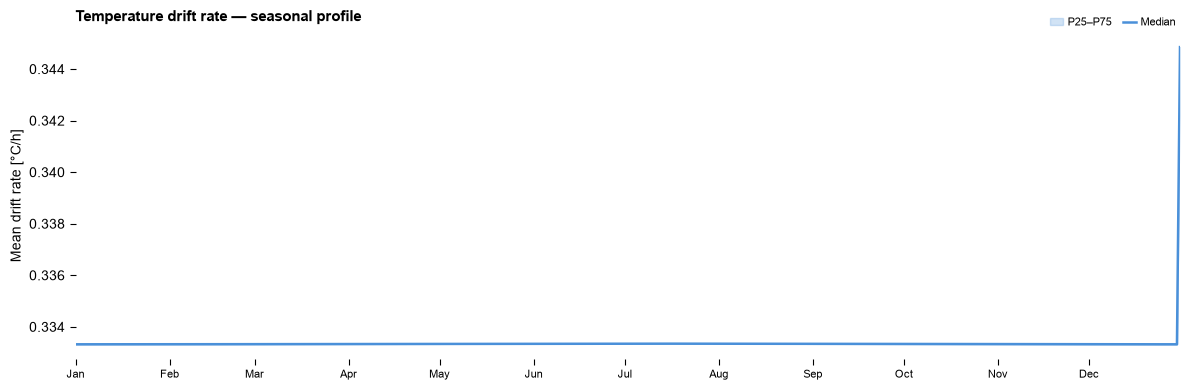

In [35]:
# Seasonal profile: pad drift array to 8760 hours, then reshape to daily
daily_drift = np.pad(drift.drift_array, ((0, 0), (0, 1)), constant_values=np.nan)
daily_drift = np.nanmean(daily_drift.reshape(drift.drift_array.shape[0], 365, 24), axis=2)

fig = plot_seasonal_profile(
    daily_drift,
    ylabel="Mean drift rate [°C/h]",
    title="Temperature drift rate — seasonal profile",
)

### 4.5 Diurnal Phase Alignment

Pearson correlation of the mean indoor daily temperature cycle vs the outdoor EPW cycle, restricted to days where the outdoor daily mean falls in a specified temperature range (default 15–28 °C). This focuses the metric on shoulder seasons when thermal coupling through ventilation is most relevant.

* **+1.0** — indoor peaks align with outdoor peaks (naturally coupled)
*  **0.0** — no relationship
* **−1.0** — inverted cycle (e.g. overcooled building peaking at night)

*Requires an EPW file. Pass `epw_path=` to `ThermalEnvironment.from_arrays()` or directly to `diurnal_phase_alignment()`.*

In [36]:
# Uncomment and set epw_path to run this metric
# phase = diurnal_phase_alignment(env, epw_path="path/to/climate.epw")
# print(phase)
# print(f"\nMean phase score:  {phase.mean_score:.3f}  (range −1 to +1)")
# print(f"Days included:     {phase.n_days_included}  (outdoor mean in 15–28 °C)")
#
# # Spatial map of Pearson correlation scores
# fig = plot_floor_map(
#     values=phase.scores,
#     grid=env.grid,
#     cmap="RdBu_r",
#     vmin=-1.0, vmax=1.0,
#     label="Phase alignment (Pearson r)",
#     title="Diurnal phase alignment — spatial distribution",
# )

---
## 5. Personal Comfort Systems (PCS)

PCS devices operate as a **post-processing step**: they modify environmental conditions
at a selected subset of grid points, then the adjusted `ThermalEnvironment` is fed back
through any comfort model or spatial metric to quantify the corrective benefit.

This makes PCS analysis fully composable with the rest of the capy workflow — no
special handling required in the comfort models themselves.

| Device | What it modifies | Default correction |
|---|---|---|
| `Fan` | air velocity | +0.5 m/s |
| `FootWarmer` | mean radiant temperature | +3.0 °C |
| `HeatedChair` | mean radiant temperature | +4.0 °C |
| `CooledChair` | mean radiant temperature | −4.0 °C |
| `PersonalHeater` | air temperature | +2.0 °C |

In [37]:
from capy.pcs import CooledChair, Fan, FootWarmer, PointSelector
from capy.comfort.pmv import calculate_pmv, PMVParameters
from capy.metrics import spatial_thermal_autonomy
from capy.viz.summary import plot_category_summary

### 5.1 Point selection

Three factory methods cover the most common selection patterns:

In [38]:
# Option A — explicit indices
corner_sel = PointSelector.from_indices([0, 1, 6, 7], n_points=grid.n_points)
print('corner_sel :', corner_sel)

# Option B — random fraction, area-weighted
half_sel = PointSelector.from_fraction(grid, fraction=0.5, seed=0)
print('half_sel   :', half_sel)

# Option C — bounding box (x in [0,2], y in [0,9])
desk_sel = PointSelector.from_bbox(grid, x=(0, 2), y=(0, 9))
print('desk_sel   :', desk_sel)

corner_sel : PointSelector(n_selected=4/12)
half_sel   : PointSelector(n_selected=6/12)
desk_sel   : PointSelector(n_selected=12/12)


### 5.2 Fan — always-on

Apply a desk fan to the selected area (bounding box = left third of the floor plan).
The fan increases local air velocity; the updated `ThermalEnvironment` is then passed
to `calculate_pmv` to quantify the comfort benefit.

In [39]:
# Baseline PMV
result_base = calculate_pmv(env)

# Apply fan — always active
fan = Fan(delta_v=0.5)
env_fan = fan.apply(env, points=desk_sel)

# Velocity before and after at a selected vs unselected point
v_sel   = env_fan.get('air_velocity')[0, 0]
v_unsel = env_fan.get('air_velocity')[-1, 0]
print(f'Selected point velocity   : {v_sel:.2f} m/s  (was 0.10 m/s)')
print(f'Unselected point velocity : {v_unsel:.2f} m/s  (unchanged)')

result_fan = calculate_pmv(env_fan)

Selected point velocity   : 0.60 m/s  (was 0.10 m/s)
Unselected point velocity : 0.60 m/s  (unchanged)


### 5.3 Fan — comfort-triggered

Activate the fan **only during discomfort hours** — the most realistic simulation of
user behaviour (device switched on when too warm, off otherwise).

`ComfortResult.is_comfortable()` returns a `(n_points, n_hours)` boolean mask.
Inverting it gives the discomfort hours, which become the `when` argument.

In [40]:
# Only switch on when a point is in discomfort
discomfort_mask = ~result_base.is_comfortable()   # (n_points, n_hours) bool

env_fan_ct = fan.apply(env, points=desk_sel, when=discomfort_mask)
result_fan_ct = calculate_pmv(env_fan_ct)

# How many point-hours does the fan activate?
n_active = (discomfort_mask[desk_sel.resolve()]).sum()
print(f'Fan active at {n_active:,} point-hours  '
      f'({100 * n_active / (desk_sel.resolve().sum() * N_HOURS):.1f}% of selected point-hours)')

Fan active at 69,126 point-hours  (65.8% of selected point-hours)


### 5.4 Stacking devices

Devices can be chained: apply one to an environment, then apply the next to the
result. Both corrections accumulate independently.

In [41]:
# Desk area: fan + foot warmer for winter heating scenario
env_stacked = fan.apply(env, points=desk_sel)                       # +0.5 m/s
env_stacked = FootWarmer(delta_mrt=3.0).apply(env_stacked, points=desk_sel)  # +3 °C MRT

pt = 0  # first selected point
v0   = env_stacked.get('air_velocity')[pt, 0]
mrt0 = env_stacked.get('mean_radiant_temperature')[pt, 0]
mrt_base = env.get('mean_radiant_temperature')[pt, 0]
print(f'Velocity   : {v0:.2f} m/s  (default 0.10 + fan 0.50)')
print(f'MRT        : {mrt0:.2f} °C  (base {mrt_base:.2f} + footwarmer +3.0)')
print(f'pcs_applied: {env_stacked.info["pcs_applied"]}')

Velocity   : 0.60 m/s  (default 0.10 + fan 0.50)
MRT        : 21.00 °C  (base 18.00 + footwarmer +3.0)
pcs_applied: True


### 5.5 Impact summary

Compare sTA for three scenarios:
- **Baseline** — no PCS
- **Fan (always-on)** — fan active at desk area throughout occupied hours
- **Fan (comfort-triggered)** — fan activates only on discomfort hours

In [42]:
scenarios = [
    ('Baseline',              result_base),
    ('Fan — always-on',       result_fan),
    ('Fan — comfort-triggered', result_fan_ct),
]

print(f'{'Scenario':<28}  sTA (τ=0.8)  Comfort frac.')
print('-' * 52)
for label, res in scenarios:
    sta  = spatial_thermal_autonomy(res, tau=0.8, schedule=schedule)
    cf   = res.comfort_fraction().mean()
    print(f'{label:<28}  {sta.annual_pct:>7.1f} %   {cf:>8.1%}')

Scenario                      sTA (τ=0.8)  Comfort frac.
----------------------------------------------------
Baseline                         15.8 %      34.2%
Fan — always-on                  15.7 %      34.9%
Fan — comfort-triggered          39.7 %      60.3%


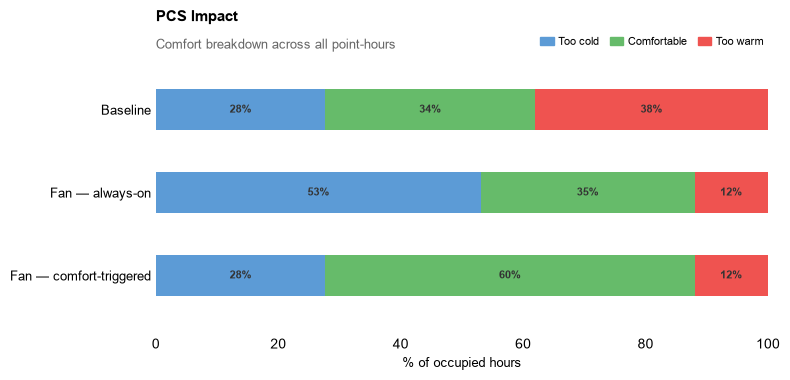

In [43]:
# Visual comparison: comfort fraction breakdown for all three scenarios
# Build (n_scenarios, 3) matrix: [cold_frac, comfortable_frac, warm_frac]
def _breakdown(result):
    d = result.discrete
    total = d.size
    return [
        100 * (d == -1).sum() / total,
        100 * (d ==  0).sum() / total,
        100 * (d == +1).sum() / total,
    ]

values_matrix = np.array([_breakdown(r) for _, r in scenarios])

fig = plot_category_summary(
    categories=[
        {'label': 'Too cold',     'color': '#5c9bd6'},
        {'label': 'Comfortable',  'color': '#66bb6a'},
        {'label': 'Too warm',     'color': '#ef5350'},
    ],
    rows=[l for l, _ in scenarios],
    values_matrix=values_matrix,
    title='PCS Impact',
    subtitle='Comfort breakdown across all point-hours',
)